# Sharma & Oberoi 2020, Figure 4 — pictures

Quiet Sun, 3 December 2015, 03:39–03:44 UT.

Figure 4 is the **mean of ~570 half-second maps**. Every comparison below is a map. His row is that 570-frame mean. Ours is the SuperUniform remake of the same visibilities, as many frames as are on disk.

Kernel: `solar-burst-multiview`. Run from the top.


## 1. How many of our frames are here?


In [1]:
from pathlib import Path
import json, re, sys
from IPython.display import Image, display

here = Path.cwd()
ROOT = here if (here / "src" / "solarburst").exists() else here.parent
sys.path.insert(0, str(ROOT / "src"))
FIG = ROOT / "figures" / "sharma2020"
OURS = ROOT / "data" / "quiet2015" / "paper_casa_su"
BANDS = ("108", "162", "217", "240")

def n_ours(lab):
    rx = re.compile(rf"^{lab}MHz_(\d{{4}})\.fits$")
    return sum(1 for p in OURS.glob(f"{lab}MHz_*.fits") if rx.match(p.name))

for lab in BANDS:
    print(f"{lab} MHz   our remake {n_ours(lab):3d} / 570")


108 MHz   our remake 129 / 570
162 MHz   our remake 127 / 570
217 MHz   our remake  56 / 570
240 MHz   our remake   0 / 570


Rebuild the PNGs if you just copied more frames from the cluster (takes a few minutes):


In [2]:
# %run ../scripts/sharma2020_fig4_visuals.py
print("PNGs live in", FIG)
print("Uncomment the line above to rebuild after a new rsync.")


PNGs live in /Users/csillag/Projects/solar-burst-multiview/figures/sharma2020
Uncomment the line above to rebuild after a new rsync.


## 2. His Figure 4

Mean of his 570 frames, paper kelvin. This is the picture the caption quotes.


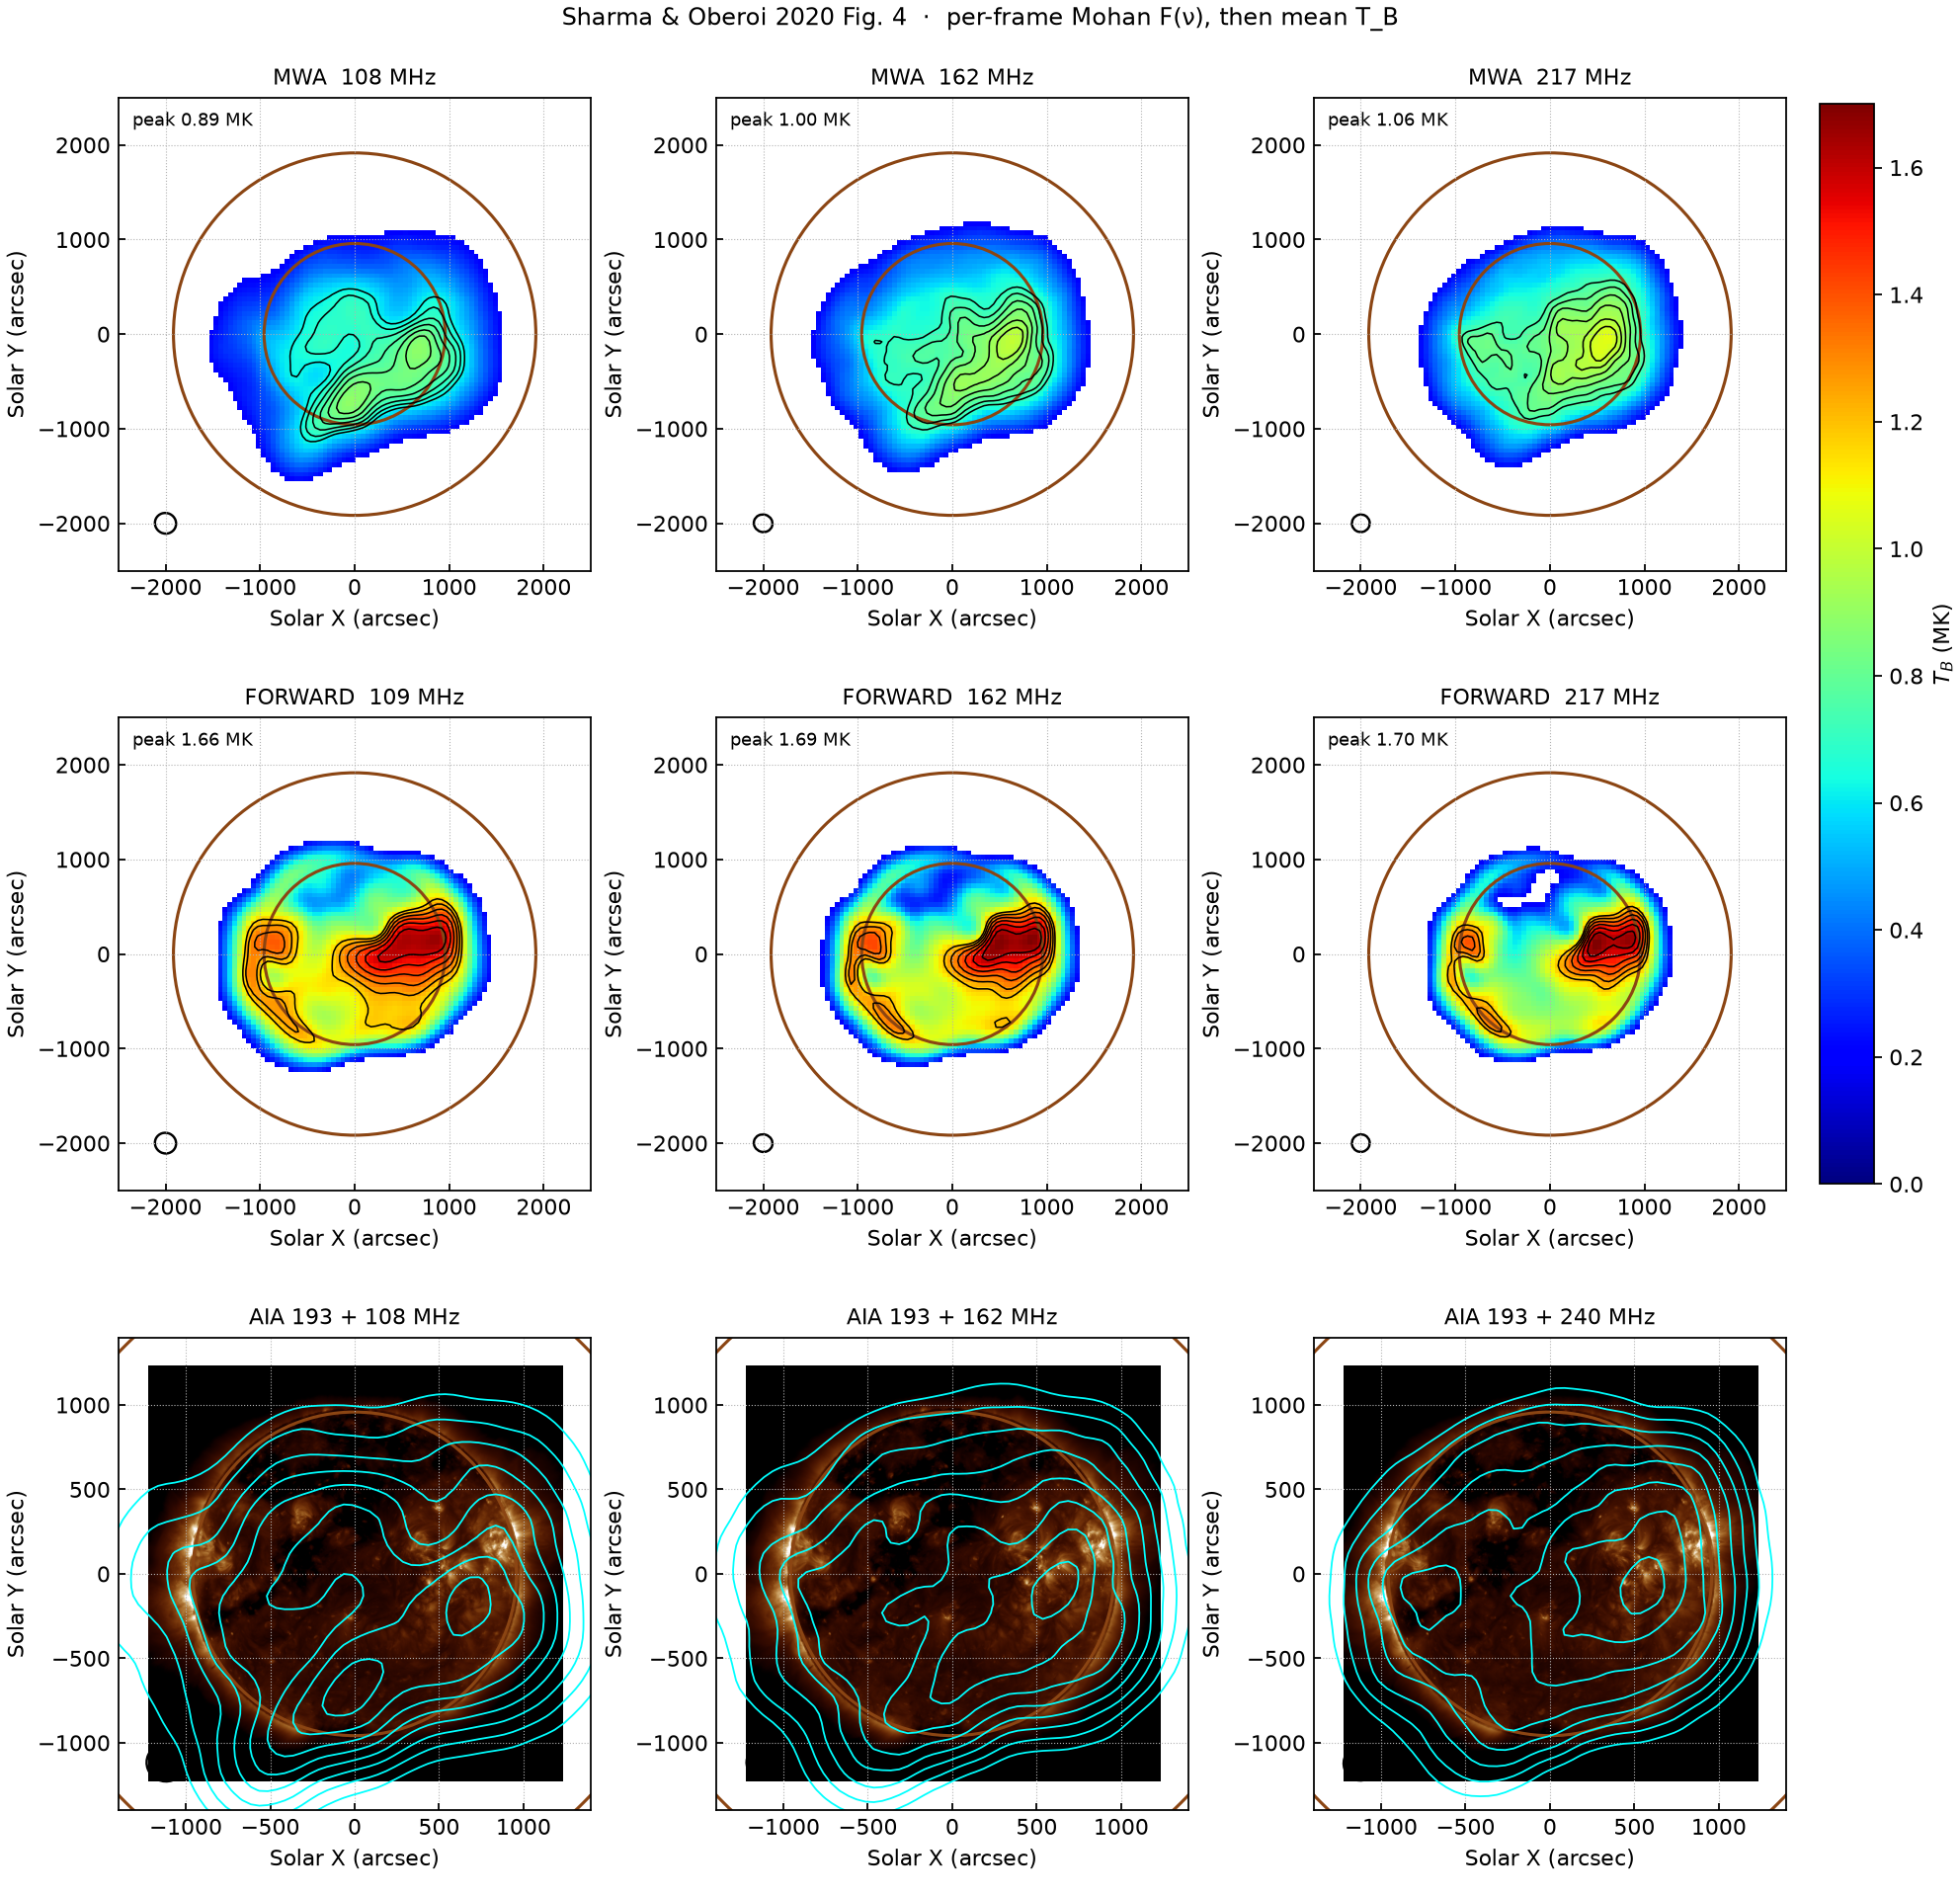

In [3]:
display(Image(filename=str(FIG / "fig4_paper.png"), width=980))


## 3. His four frequencies, same 0–1.7 million K colour as the paper


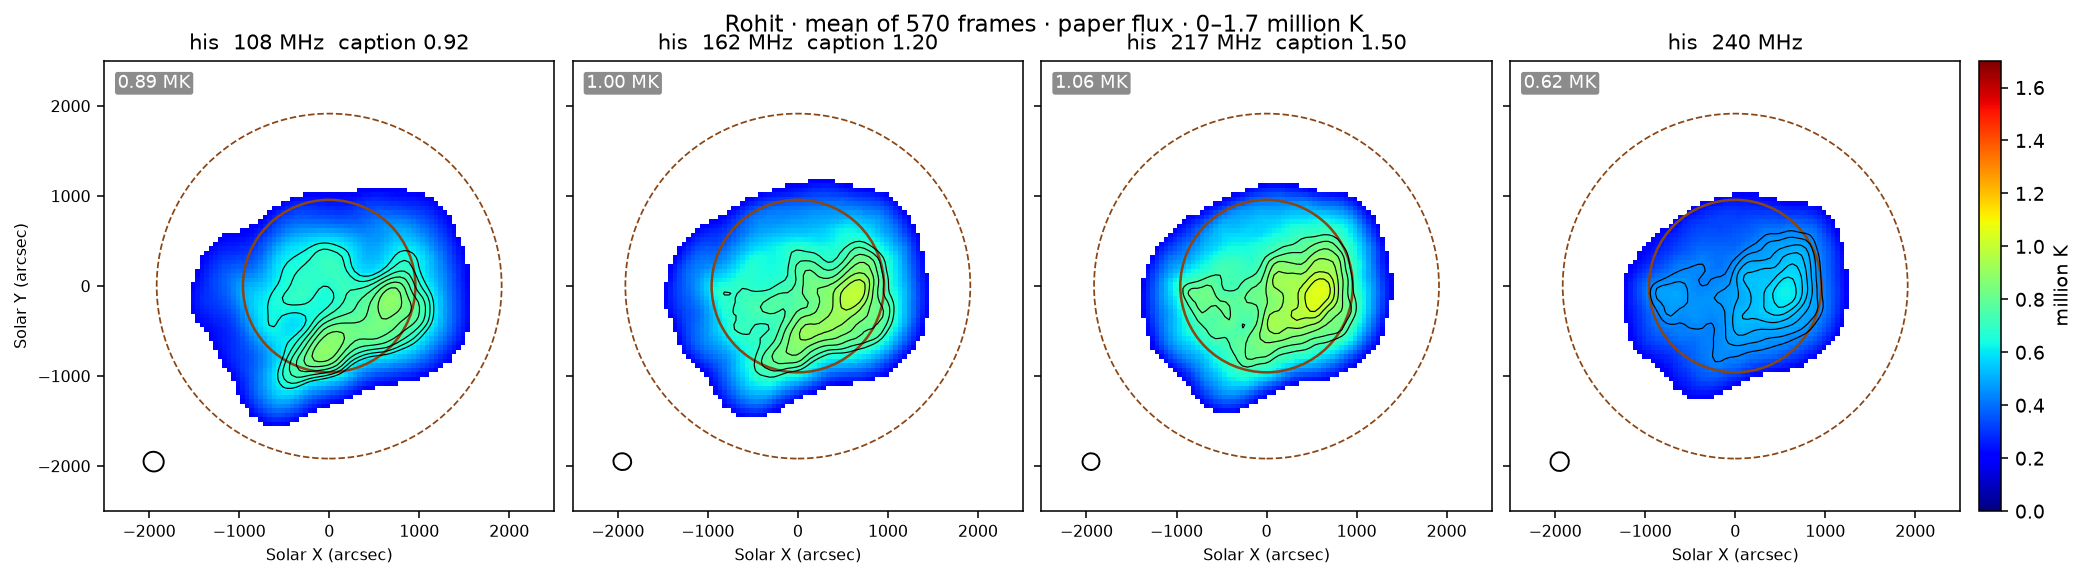

In [4]:
display(Image(filename=str(FIG / "fig4_his_mean.png"), width=1100))


## 4. His vs ours — same colour scale

Top = his 570-frame mean. Bottom = our remake. Brown rings are 1 and 2 solar radii. Black ellipse is the restoring beam.

Ask: is the western patch on the west, and is the disk inside the inner ring?


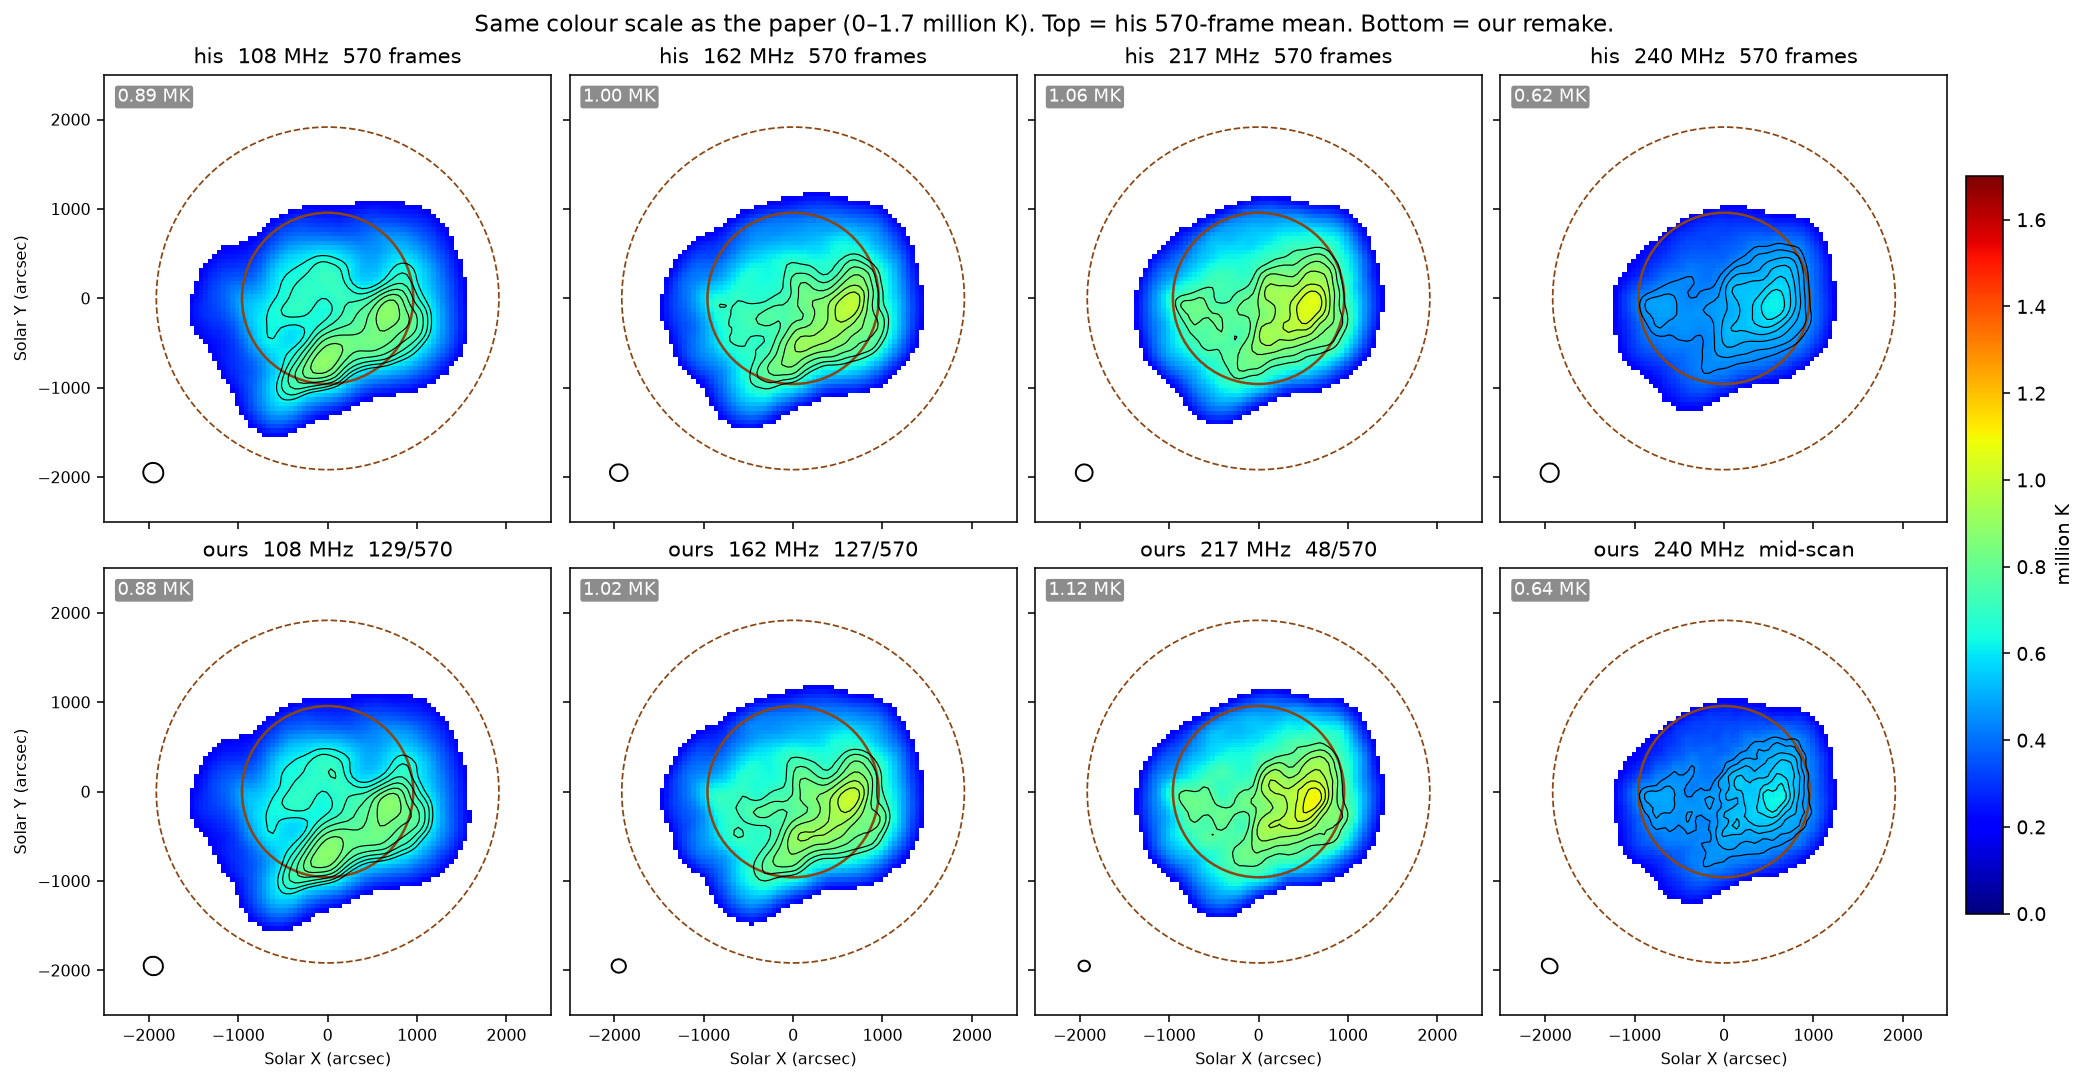

In [5]:
display(Image(filename=str(FIG / "fig4_his_vs_ours.png"), width=1100))


## 5. Same pair, each panel stretched to its own peak

Ignore the kelvin number. This is the shape comparison.


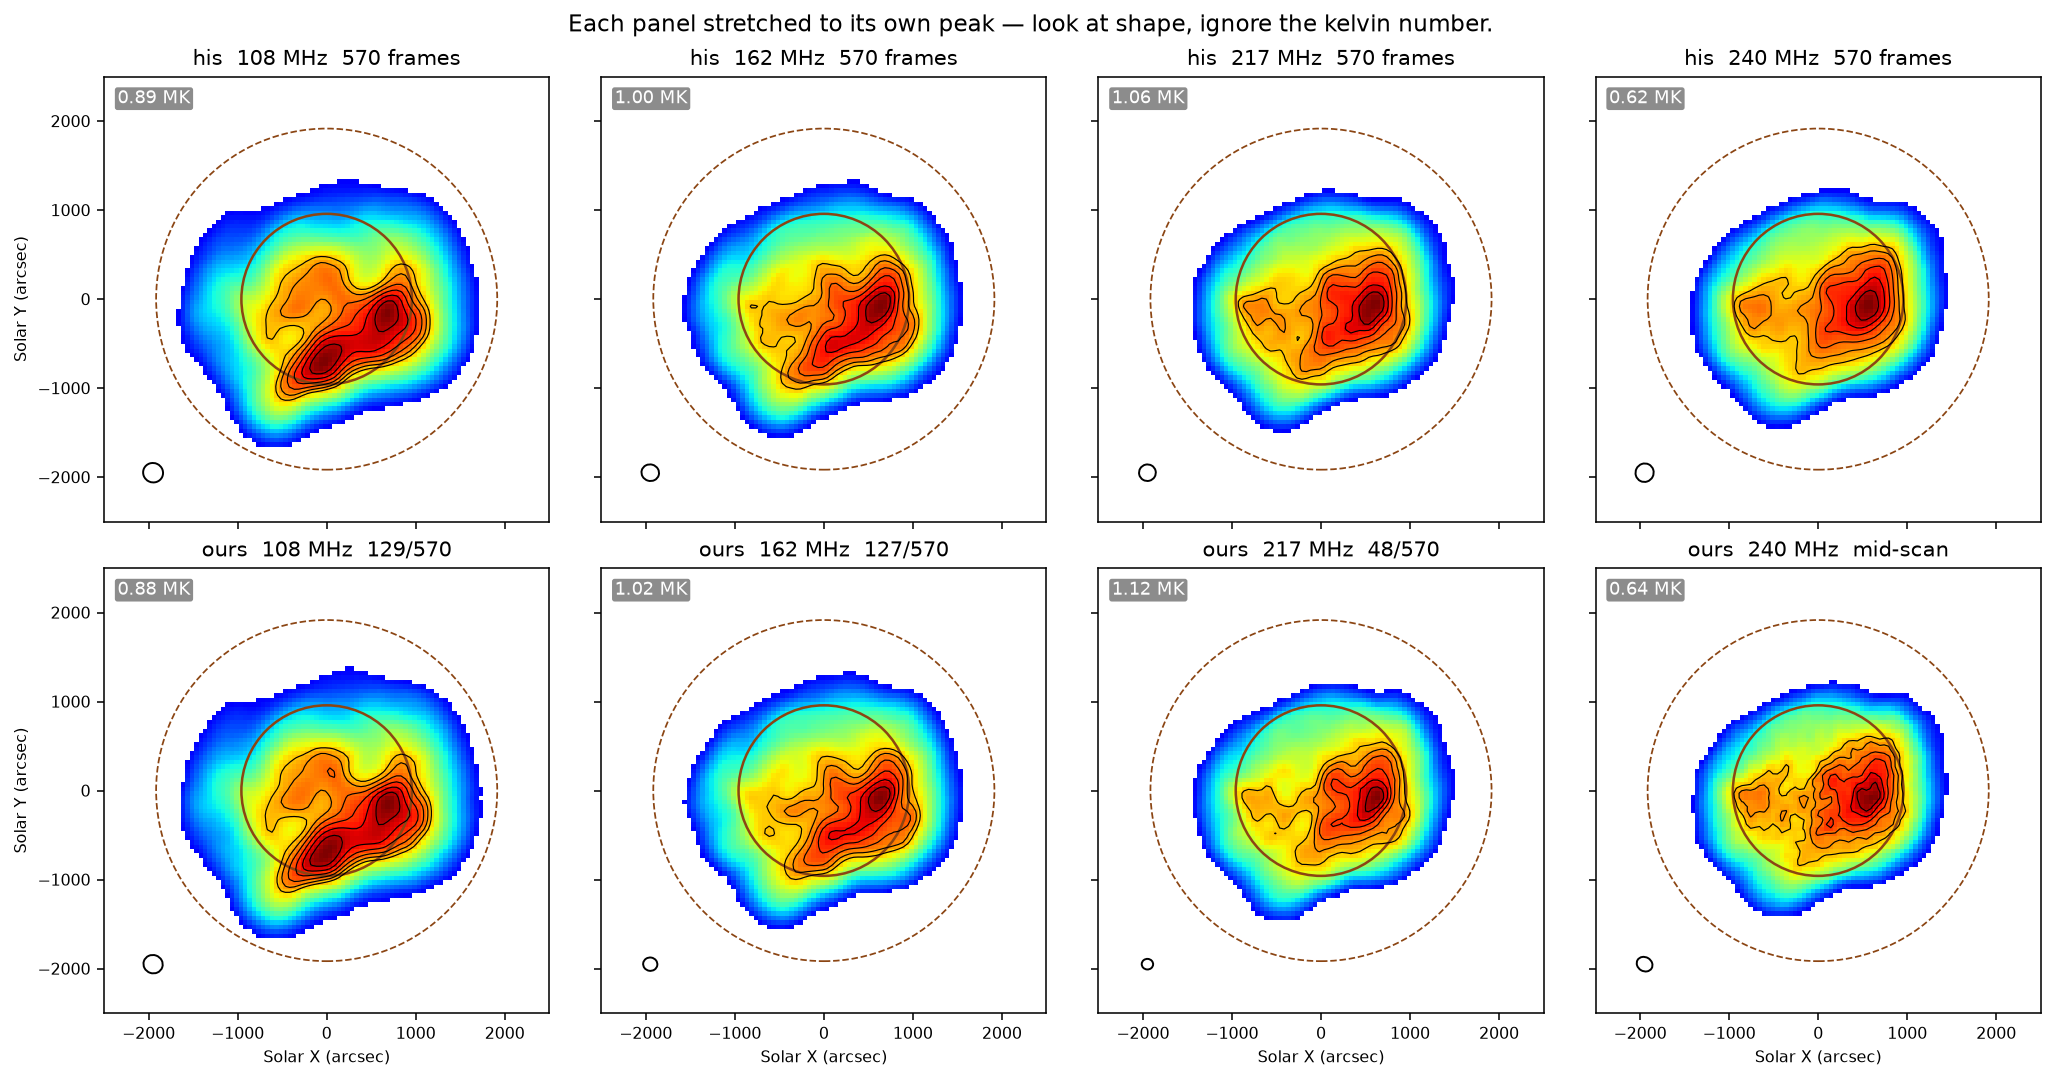

In [6]:
display(Image(filename=str(FIG / "fig4_his_vs_ours_shape.png"), width=1100))


## 6. Our remake alone (the running mean of frames on disk)


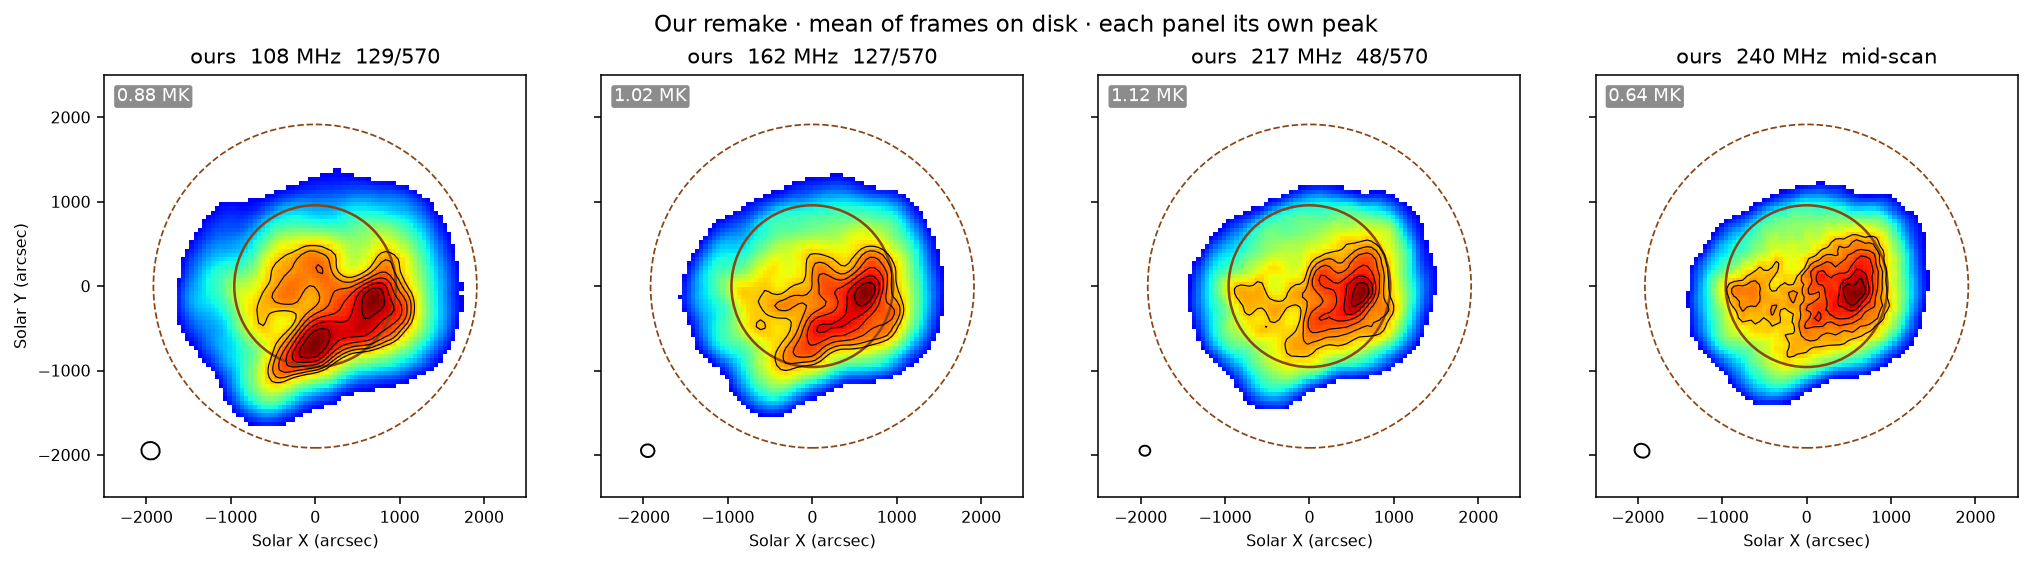

In [7]:
display(Image(filename=str(FIG / "fig4_ours_mean.png"), width=1100))


## 7. Ours minus his

Red = we are hotter. Blue = he is hotter. Same sun-centred crop.


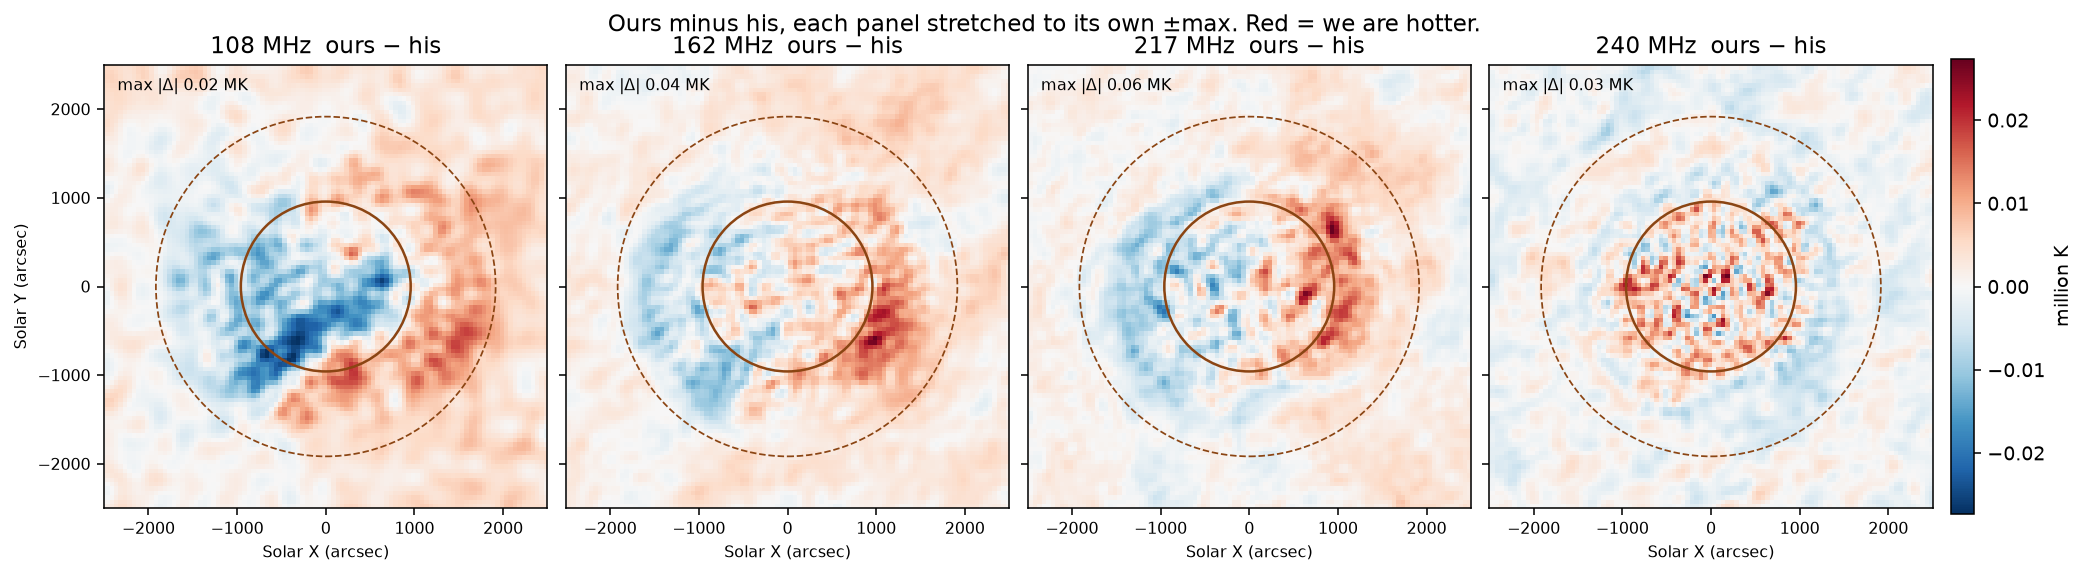

In [8]:
display(Image(filename=str(FIG / "fig4_diff.png"), width=1100))


## 8. A strip of our half-second frames

These are the pictures going into the mean. They should all look like the same quiet Sun, not a burst movie.


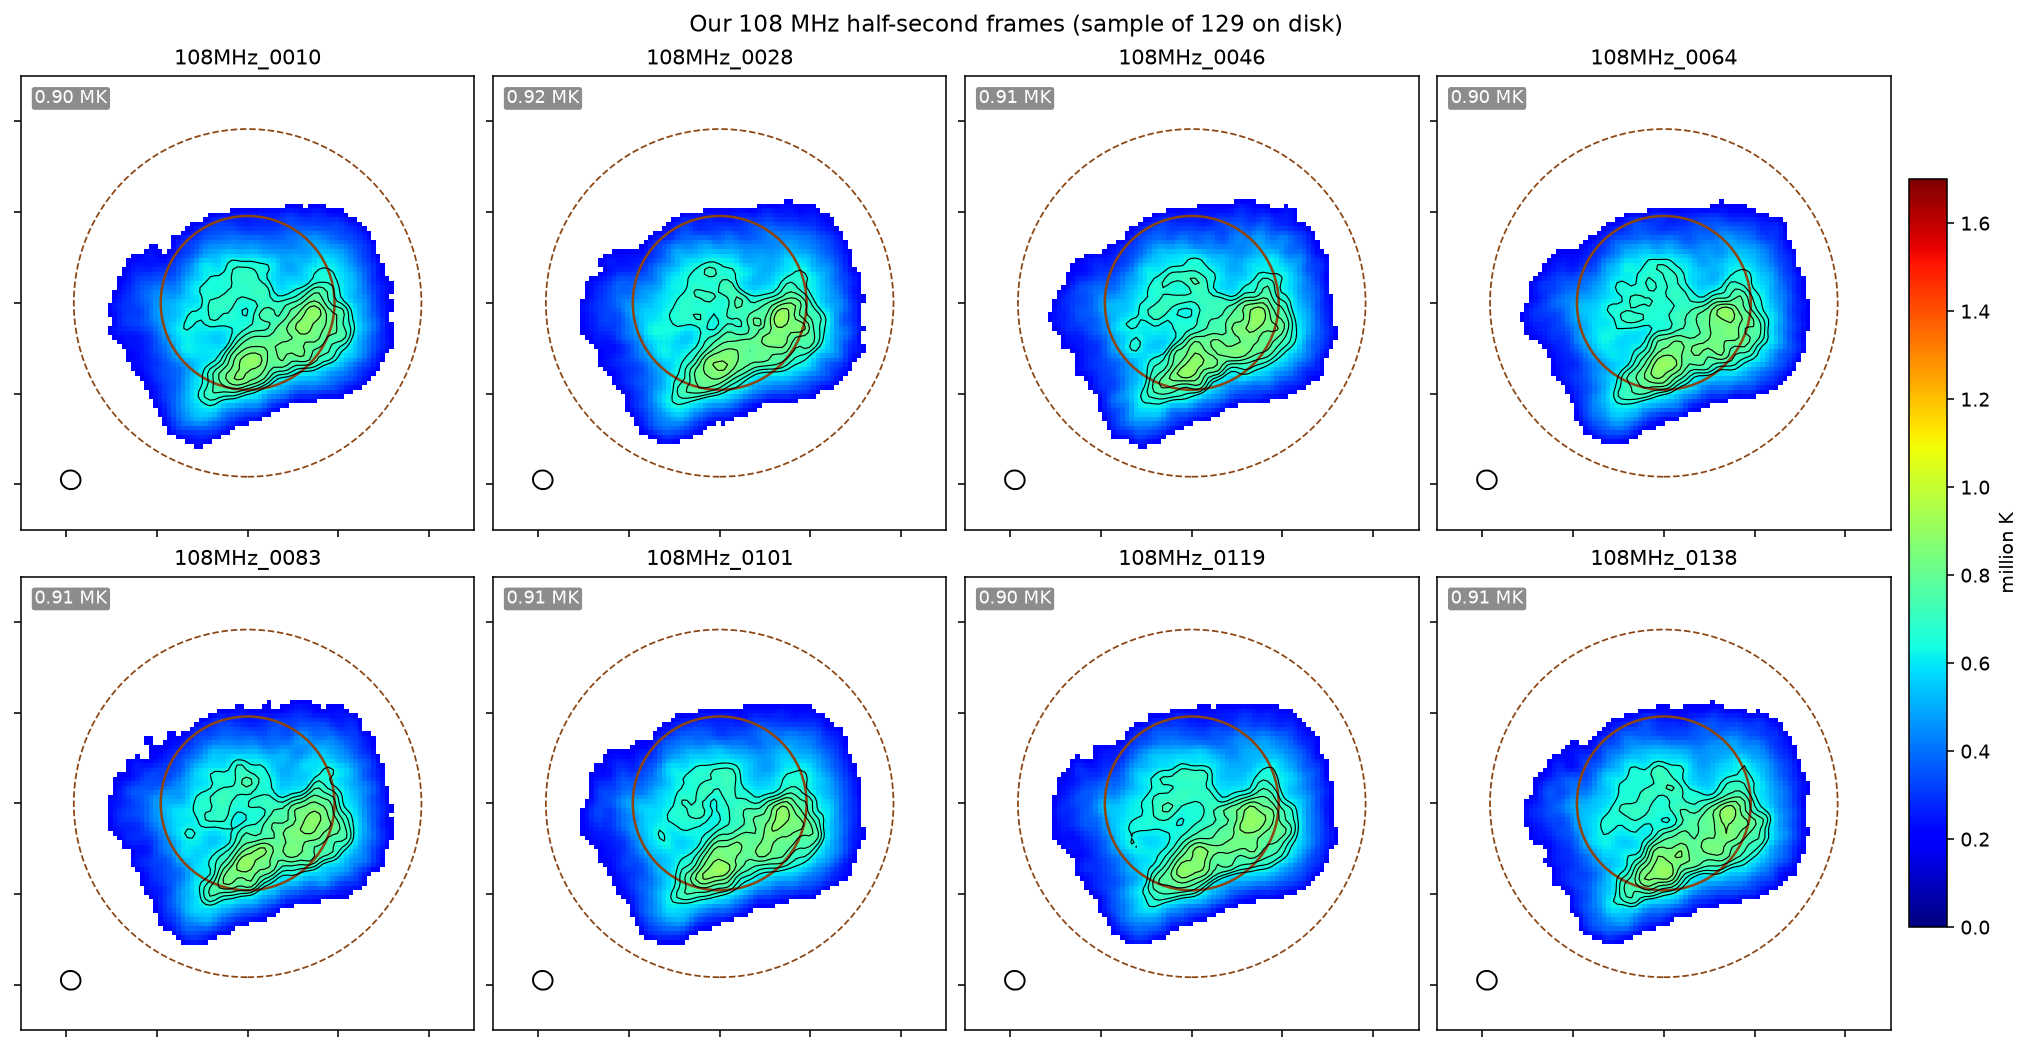

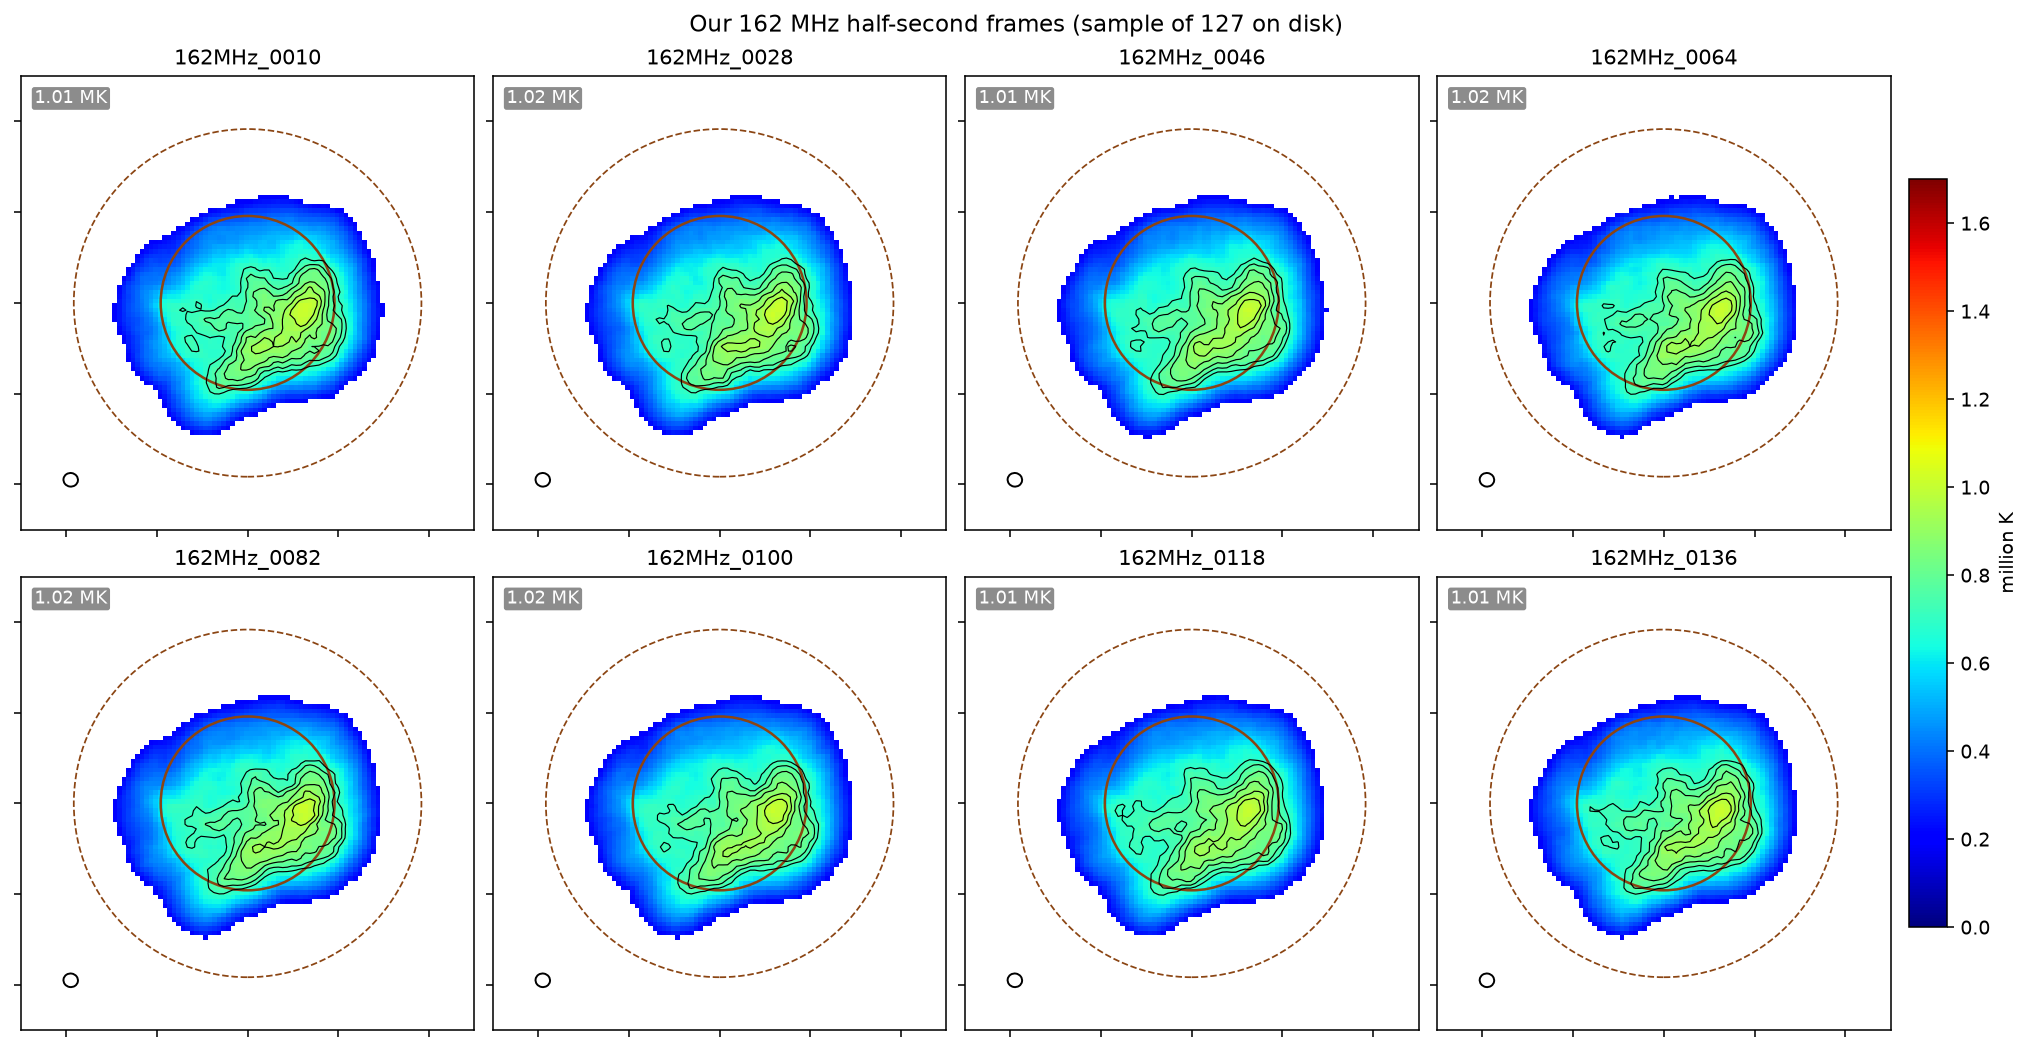

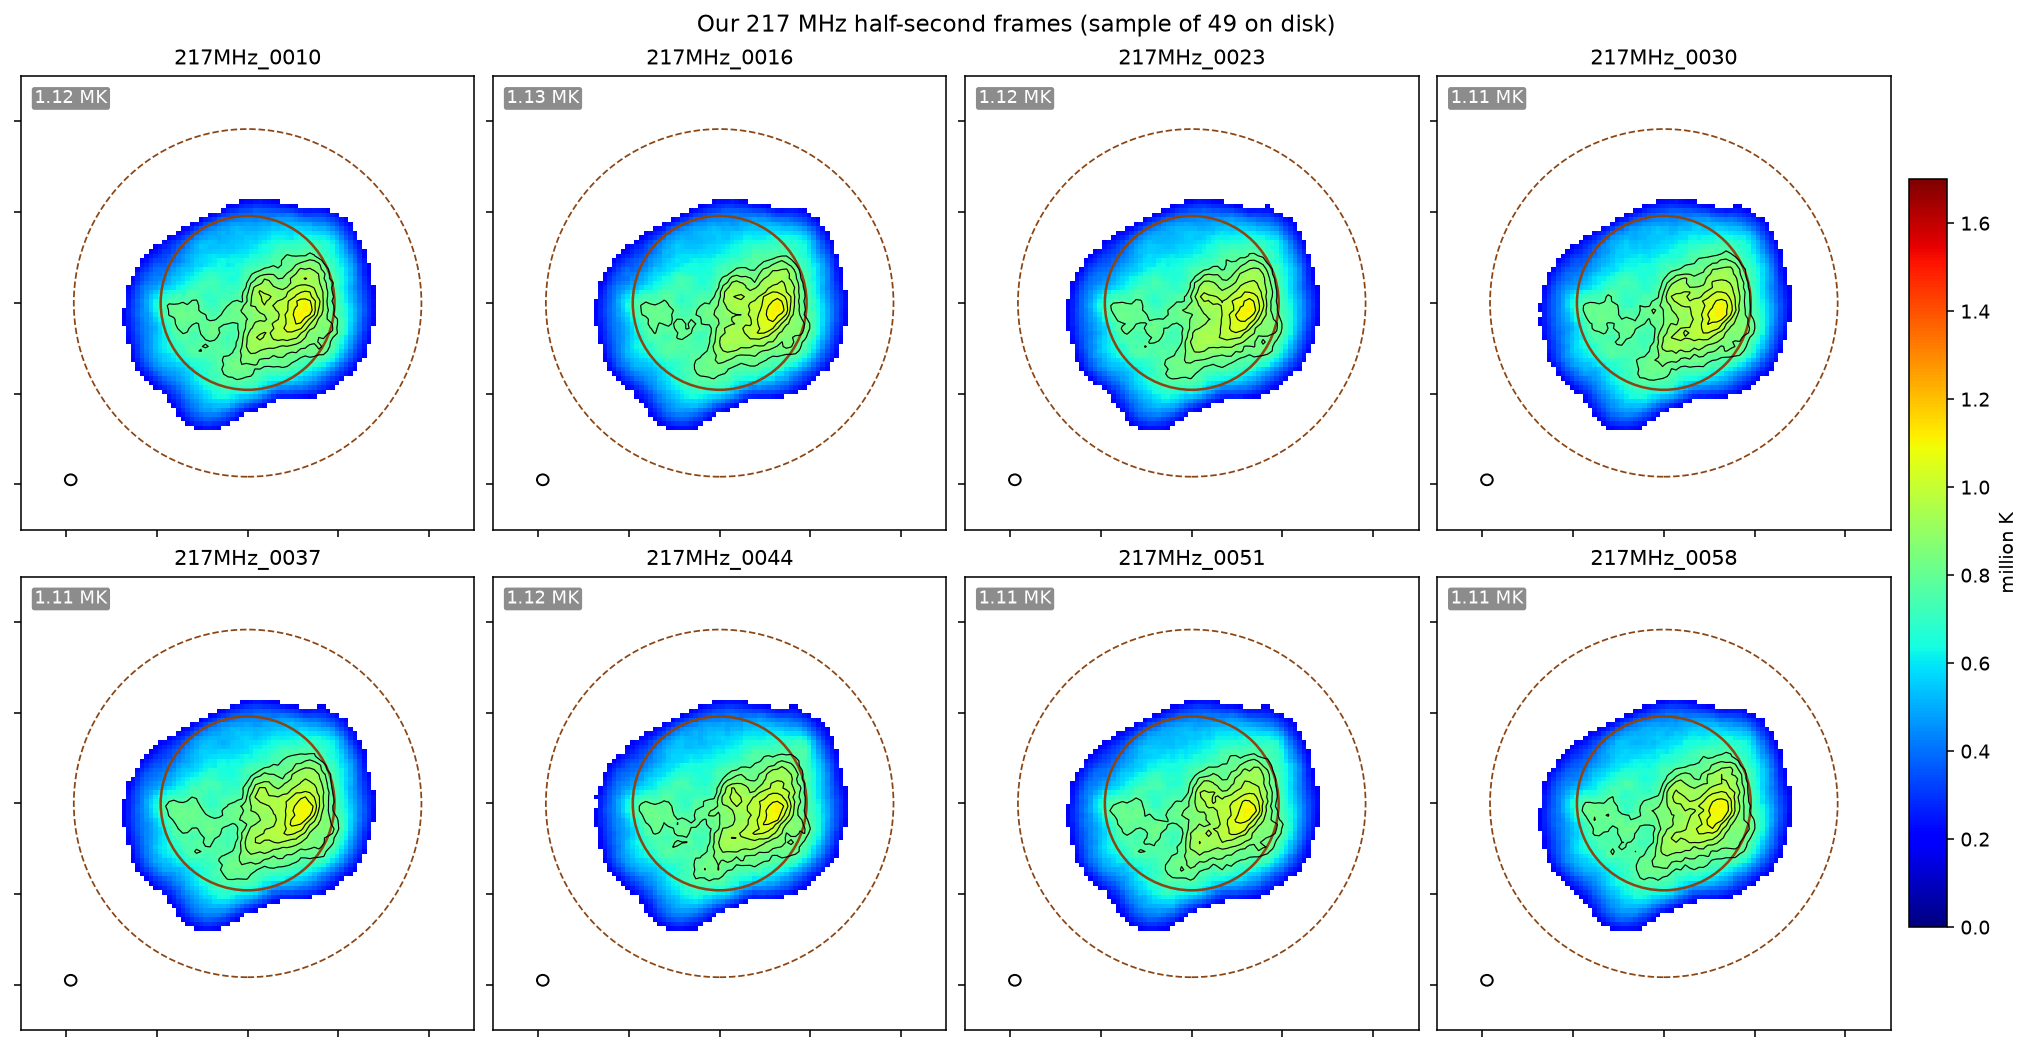

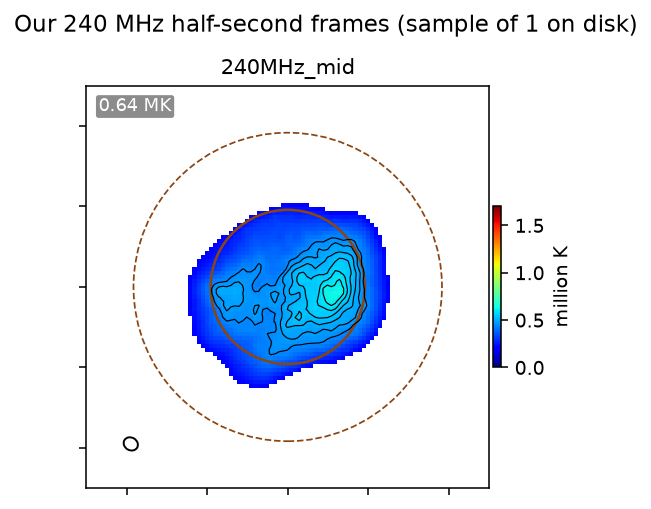

In [9]:
for lab in BANDS:
    p = FIG / f"fig4_ours_strip_{lab}.png"
    if p.exists():
        display(Image(filename=str(p), width=1100))
    else:
        print(f"no strip yet for {lab} MHz")


## 9. Numbers that go with the pictures


In [10]:
rows = json.loads((FIG / "fig4_ours_summary.json").read_text())
print(f"{'MHz':>4}  {'caption':>8}  {'his MK':>7}  {'ours MK':>8}  {'n':>5}  {'his beam':>12}  {'ours beam':>12}")
for r in rows:
    cap = "—" if r["caption_mk"] is None else f"{r['caption_mk']:.2f}"
    ob = "×".join(f"{x:.0f}" for x in r.get("ours_beam_arcsec", [])) or "—"
    hb = "×".join(f"{x:.0f}" for x in r["his_beam_arcsec"])
    n = r.get("ours_n", 0)
    omk = r.get("ours_peak_mk")
    omk_s = "—" if omk is None else f"{omk:.2f}"
    print(f"{r['mhz']:>4}  {cap:>8}  {r['his_peak_mk']:7.2f}  {omk_s:>8}  {n:5d}  {hb:>12}  {ob:>12}")


 MHz   caption   his MK   ours MK      n      his beam     ours beam
 108      0.92     0.89      0.88    129       225×217       217×205
 162      1.20     1.00      1.02    127       198×186       160×150
 217      1.50     1.06      1.11     48       188×186       128×119
 240         —     0.62      0.64      1       209×202       183×157


## 10. What to look at

- Shape: disk + western patch on both sides. That is the same quiet Sun.
- 108 MHz kelvin on *his* 570-frame mean is 0.89 against the caption 0.92.
- 162 and 217 MHz stay low on his maps (1.00 vs 1.20, 1.06 vs 1.50). That leftover is the flux (simple tile vs unpublished FEKO), not a wrong picture.
- Our restoring beam at 162 and 217 MHz is sharper than his. That is CASA 6.6 `tclean` vs his CASA 5.3 `clean`, and it is visible in the maps.
- Our mean is still a partial scan. Re-run cell 1’s rebuild after the cluster reaches 570/570.
